# 👋 Welcome to the Mondrian Conformal Prediction Tutorial

In this tutorial, we will use *puncc* to build prediction sets and intervals with coverage guarantees within categories. We will begin with **Mondrian classification**, where the categories are the possible class labels, and then implement **Mondrian regression**, where the categories are bins of estimated prediction difficulty.

By the end of this notebook, you will be able to:

- use `ClassConditionalLAC` to construct class-conditional prediction sets;
- combine `GroupConditionalMixin` and `SplitConformalRegression` to build a Mondrian regressor;
- compare both approaches with their marginal conformal baselines;
- evaluate coverage and prediction-set size **within each category**.

**Table of contents**

- [🛠️ Setup](#setup)
- [📊 What makes a conformal predictor Mondrian?](#mondrian)
- [🏷️ Mondrian Classification](#classification)
    - [💾 Imbalanced classification dataset](#classification-data)
    - [🔮 A probability predictor](#classification-model)
    - [⚙️ Class-conditional calibration](#classification-calibration)
    - [📏 Coverage and set size by class](#classification-metrics)
    - [🔍 Inspecting the class-specific thresholds](#classification-thresholds)
- [📈 Mondrian Regression](#regression)
    - [💾 Heteroskedastic regression dataset](#regression-data)
    - [🔮 Learning the mean and difficulty](#regression-model)
    - [🗂️ Defining the Mondrian categories](#regression-groups)
    - [⚙️ Group-conditional calibration](#regression-calibration)
    - [📏 Coverage and interval width by category](#regression-metrics)
    - [🔍 Inspecting the group-specific thresholds](#regression-thresholds)
- [✅ Choosing and evaluating categories](#takeaways)

**Links**

- [puncc on GitHub](https://github.com/deel-ai/puncc)
- [📘 Documentation](https://deel-ai.github.io/puncc/)

**References**

- Boström and Johansson, [*Mondrian Conformal Regressors*](https://proceedings.mlr.press/v128/bostrom20a.html), 2020, §3.
- Ding et al., [*Class-Conditional Conformal Prediction with Many Classes*](https://arxiv.org/abs/2306.09335), 2023, classwise baseline. We use separate classes, rather than the paper's proposed class-clustering method.

## 🛠️ Setup <a class="anchor" id="setup"></a>

In [1]:
from deel.puncc.config import set_backend

set_backend("numpy")

import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from deel.puncc.classification import ClassConditionalLAC, LAC
from deel.puncc.core.conformal import GroupConditionalMixin
from deel.puncc.metrics import (
    classification_mean_coverage,
    classification_mean_size,
    regression_mean_coverage,
    regression_sharpness,
)
from deel.puncc.plotting import plot_prediction_intervals
from deel.puncc.regression import SplitConformalRegression

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
alpha = 0.1  # Target coverage: 90%.
print(f"Target coverage: {1 - alpha:.0%}")

Target coverage: 90%


## 📊 What makes a conformal predictor Mondrian? <a class="anchor" id="mondrian"></a>

A standard conformal predictor aims for **marginal coverage**:

$$\mathbb{P}\{Y_{\mathrm{new}}\in\mathcal{C}(X_{\mathrm{new}})\}\geq 1-\alpha.$$

A Mondrian predictor divides observations into categories and calibrates within each category. The category rule is often called a **taxonomy**. In this notebook, we consider two choices:

| Task | Category | Coverage target | V1 implementation |
|---|---|---|---|
| Classification | True class $Y=k$ | $\mathbb{P}\{Y\in\mathcal{C}(X)\mid Y=k\}\geq1-\alpha$ | `ClassConditionalLAC` |
| Regression | Observable group $g(X)=b$ | $\mathbb{P}\{Y\in\mathcal{C}(X)\mid g(X)=b\}\geq1-\alpha$ | `GroupConditionalMixin` + `SplitConformalRegression` |

The classification rule depends on the candidate label: we must test every possible class when building the prediction set. The regression rule depends only on information available at prediction time, so each observation can be routed to one category.

### Calibrating prediction sets/intervals by category

*Puncc* builds prediction sets/intervals separately for each category, using the calibration scores in that category. It also adjusts the cutoff to account for the amount of calibration data available. What matters is **the number of calibration examples in that category**, rather than the size of the full calibration dataset. Puncc handles this automatically; the small example below will help us inspect the results.

For the usual split-conformal guarantee, calibration and new observations must be exchangeable, with the fitted predictor and category rule fixed independently of calibration. We will use i.i.d. generated observations, disjoint fit/calibration/test subsets, and training-only category construction.

In [2]:
def conformal_threshold(scores, alpha):
    """Independent reference for the corrected, unweighted threshold."""
    scores = np.asarray(scores, dtype=np.float64)
    augmented_scores = np.sort(np.append(scores, np.inf))
    rank = int(np.ceil((len(scores) + 1) * (1 - alpha)))
    return augmented_scores[rank - 1]

## 🏷️ Mondrian Classification <a class="anchor" id="classification"></a>

Let us begin with **label-conditional Mondrian classification**. We will compare ordinary LAC with `ClassConditionalLAC`, using the same classifier model and calibration observations.

For LAC, the nonconformity score is

$$s(x,y)=1-\hat p_y(x).$$

Ordinary LAC uses one threshold $q$ across all classes. `ClassConditionalLAC` computes a threshold $q_k$ from calibration observations whose **true label** is $k$, and returns

$$\mathcal{C}(x)=\{k:1-\hat p_k(x)\leq q_k\}.$$

We do not know the true label at prediction time. Instead, each candidate class is tested against its own threshold. 

### 💾 Imbalanced classification dataset <a class="anchor" id="classification-data"></a>

We generate a two-dimensional, three-class problem. The classes have different frequencies and spreads, so a single global threshold can hide differences in classwise coverage.

We keep three disjoint subsets:

- **fit**: train the probability model
- **calibration**: compute conformal scores
- **test**: evaluate prediction sets

We randomly split the i.i.d. observations without fixing the class counts in each subset. The class counts are therefore allowed to vary.

Subset           Samples       Class counts (0, 1, 2)
Fit                 4500             [2956 1092  452]
Calibration         2250             [1440  606  204]
Test                2250             [1494  526  230]


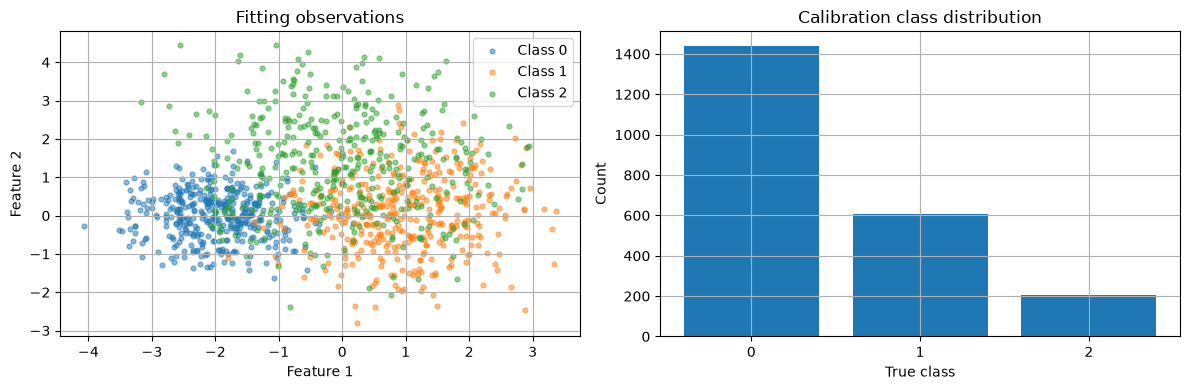

In [3]:
rng_cls = np.random.default_rng(42)
n_classes = 3
y_cls = rng_cls.choice(n_classes, size=9000, p=[0.65, 0.25, 0.10])
centers = np.array([[-2.0, 0.0], [1.0, 0.0], [0.0, 1.4]])
spreads = np.array([0.65, 0.9, 1.25])
X_cls = centers[y_cls] + spreads[y_cls, None] * rng_cls.normal(
    size=(len(y_cls), 2)
)

X_cls_fit, X_cls_remaining, y_cls_fit, y_cls_remaining = train_test_split(
    X_cls, y_cls, test_size=0.5, random_state=42
)
X_cls_calib, X_cls_test, y_cls_calib, y_cls_test = train_test_split(
    X_cls_remaining, y_cls_remaining, test_size=0.5, random_state=43
)

print(f"{'Subset':<15} {'Samples':>8} {'Class counts (0, 1, 2)':>28}")
for name, labels in [
    ("Fit", y_cls_fit),
    ("Calibration", y_cls_calib),
    ("Test", y_cls_test),
]:
    print(
        f"{name:<15} {len(labels):>8} {str(np.bincount(labels, minlength=3)):>28}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k in range(n_classes):
    points = X_cls_fit[y_cls_fit == k][:400]
    axes[0].scatter(
        points[:, 0], points[:, 1], s=12, alpha=0.5, label=f"Class {k}"
    )
axes[0].set(
    xlabel="Feature 1", ylabel="Feature 2", title="Fitting observations"
)
axes[0].legend()
axes[1].bar(np.arange(n_classes), np.bincount(y_cls_calib, minlength=n_classes))
axes[1].set(
    xlabel="True class",
    ylabel="Count",
    title="Calibration class distribution",
    xticks=np.arange(n_classes),
)
plt.tight_layout()
plt.show()

### 🔮 A probability predictor <a class="anchor" id="classification-model"></a>

Classification methods expect a matrix of **class probabilities**, with shape `(n_samples, n_classes)`. A scikit-learn classifier's usual `predict` method returns labels, so we expose `predict_proba` through a small callable adapter.

The calibration labels must be integer column indices `0, ..., K-1`. Here, the model's probability columns follow that order.

In [4]:
class ProbabilityPredictor:
    """Expose a scikit-learn classifier through puncc's callable interface."""

    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def __call__(self, X):
        return self.model.predict_proba(X)


probability_model = ProbabilityPredictor(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
)

mondrian_classifier = ClassConditionalLAC(model=probability_model)
mondrian_classifier.fit(X_cls_fit, y_cls_fit)

example_probabilities = probability_model(X_cls_test[:3])
print("Probability matrix shape:", example_probabilities.shape)
print(np.round(example_probabilities, 3))

Probability matrix shape: (3, 3)
[[0.958 0.03  0.012]
 [0.    0.853 0.146]
 [0.991 0.003 0.007]]


### ⚙️ Class-conditional calibration <a class="anchor" id="classification-calibration"></a>

Now we calibrate the Mondrian classifier. We also construct ordinary LAC around the **same fitted model**, without training it again. This keeps the comparison focused on global versus class-specific calibration.

The method `predict` returns a `ConformalPrediction` containing the base prediction and its conformal set. You can access named attributes or unpack it into two values.

In [5]:
marginal_classifier = LAC(model=probability_model)

mondrian_classifier.calibrate(X_cls_calib, y_cls_calib)
marginal_classifier.calibrate(X_cls_calib, y_cls_calib)

classwise_result = mondrian_classifier.predict(X_cls_test, alpha=alpha)
cls_probabilities, classwise_sets = classwise_result
_, marginal_sets = marginal_classifier.predict(X_cls_test, alpha=alpha)

print(f"{'Method':<22} {'Coverage':>10} {'Mean set size':>15}")
for name, prediction_sets in [
    ("LAC", marginal_sets),
    ("ClassConditionalLAC", classwise_sets),
]:
    coverage = classification_mean_coverage(y_cls_test, prediction_sets)
    size = classification_mean_size(prediction_sets)
    print(f"{name:<22} {coverage:>10.3f} {size:>15.3f}")

Method                   Coverage   Mean set size
LAC                         0.907           0.979
ClassConditionalLAC         0.903           1.254


### 📏 Coverage and set size by class <a class="anchor" id="classification-metrics"></a>

Marginal metrics are useful, but the Mondrian objective is **coverage within each true class**. Let us apply *puncc*'s coverage and set-size metrics to the corresponding test subsets.

Set size measures ambiguity: a size of one gives a single candidate, larger sets express more uncertainty, and an empty set contains no candidate. Class-conditional coverage does not force all classes to have the same average set size.

Class     Calib n   Test n    LAC cov   Mondrian cov
0            1440     1494      0.984          0.898
1             606      526      0.886          0.920
2             204      230      0.457          0.896


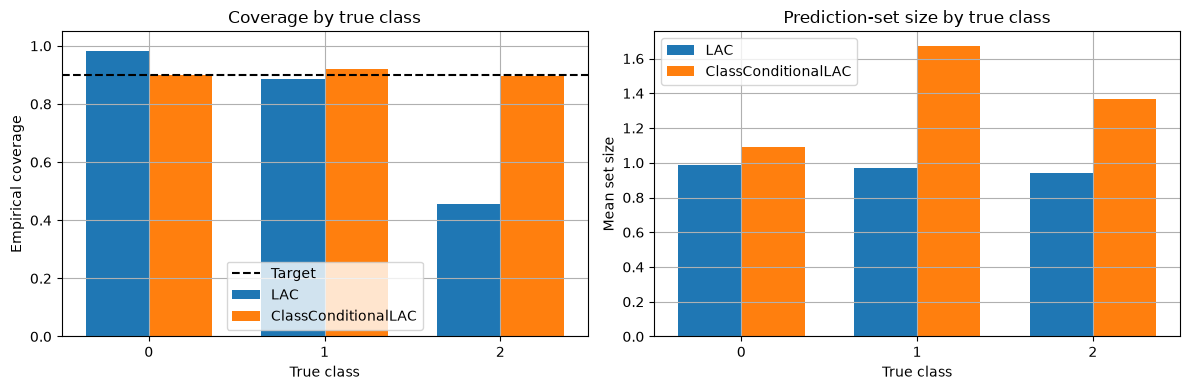

In [6]:
def classification_metrics_by_class(y_true, prediction_sets, n_classes):
    """Evaluate sets on the test observations belonging to each true class."""
    coverages, sizes = [], []
    for k in range(n_classes):
        indices = np.flatnonzero(y_true == k)
        selected_sets = [prediction_sets[i] for i in indices]
        if len(indices) == 0:
            coverages.append(np.nan)
            sizes.append(np.nan)
            continue
        coverages.append(
            classification_mean_coverage(y_true[indices], selected_sets)
        )
        sizes.append(classification_mean_size(selected_sets))
    return np.asarray(coverages), np.asarray(sizes)


cls_metrics = {
    "LAC": classification_metrics_by_class(
        y_cls_test, marginal_sets, n_classes
    ),
    "ClassConditionalLAC": classification_metrics_by_class(
        y_cls_test, classwise_sets, n_classes
    ),
}

print(
    f"{'Class':<8} {'Calib n':>8} {'Test n':>8} {'LAC cov':>10} {'Mondrian cov':>14}"
)
for k in range(n_classes):
    print(
        f"{k:<8} {(y_cls_calib == k).sum():>8} {(y_cls_test == k).sum():>8} "
        f"{cls_metrics['LAC'][0][k]:>10.3f} "
        f"{cls_metrics['ClassConditionalLAC'][0][k]:>14.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(n_classes)
width = 0.36
for offset, (name, (coverage, size)) in zip(
    [-width / 2, width / 2], cls_metrics.items()
):
    axes[0].bar(positions + offset, coverage, width, label=name)
    axes[1].bar(positions + offset, size, width, label=name)
axes[0].axhline(1 - alpha, color="black", linestyle="--", label="Target")
axes[0].set(
    ylabel="Empirical coverage", ylim=(0, 1.05), title="Coverage by true class"
)
axes[1].set(ylabel="Mean set size", title="Prediction-set size by true class")
for ax in axes:
    ax.set(xlabel="True class", xticks=positions)
    ax.legend()
plt.tight_layout()
plt.show()

Notice how the comparison changes when we look at each class separately. A global threshold can cover the frequent class well while missing more observations from a rarer class. Classwise calibration adjusts the threshold to each class's calibration scores.

Let us also inspect a few actual predictions.

In [7]:
# Select two test observations from each true class.
shown_indices = np.concatenate(
    [np.flatnonzero(y_cls_test == k)[:2] for k in range(n_classes)]
)
print(f"{'True':<6} {'Probabilities':<25} {'LAC set':<15} {'Mondrian set'}")
for i in shown_indices:
    probabilities = np.array2string(cls_probabilities[i], precision=2)
    print(
        f"{y_cls_test[i]:<6} {probabilities:<25} "
        f"{str(marginal_sets[i].tolist()):<15} {classwise_sets[i].tolist()}"
    )

True   Probabilities             LAC set         Mondrian set
0      [0.96 0.03 0.01]          [0]             [0]
0      [0.99 0.   0.01]          [0]             [0]
1      [1.61e-04 8.53e-01 1.46e-01] [1]             [1, 2]
1      [0.   0.99 0.01]          [1]             [1]
2      [0.12 0.06 0.81]          [2]             [2]
2      [0.03 0.28 0.68]          [2]             [2]


### 🔍 Inspecting the class-specific thresholds <a class="anchor" id="classification-thresholds"></a>

To make the construction concrete, we can recover the true-label calibration scores and compute the corrected quantile for each class.

We then verify that the returned sets follow the LAC inclusion rule:

In [8]:
calib_probabilities = probability_model(X_cls_calib)
cls_scores = 1 - calib_probabilities[np.arange(len(y_cls_calib)), y_cls_calib]
class_thresholds = np.array(
    [
        conformal_threshold(cls_scores[y_cls_calib == k], alpha)
        for k in range(n_classes)
    ]
)

print(f"{'Class':<8} {'Calibration size':>18} {'Threshold':>12}")
for k, threshold in enumerate(class_thresholds):
    print(f"{k:<8} {(y_cls_calib == k).sum():>18} {threshold:>12.3f}")

for probabilities, returned_set in zip(cls_probabilities, classwise_sets):
    expected_set = np.flatnonzero(probabilities >= 1 - class_thresholds)
    np.testing.assert_array_equal(returned_set, expected_set)
print("All prediction sets match the class-specific LAC thresholds.")

Class      Calibration size    Threshold
0                      1440        0.143
1                       606        0.600
2                       204        0.962
All prediction sets match the class-specific LAC thresholds.


### What happens if a class is absent from calibration?

*Puncc* assigns an infinite threshold to a missing class. With LAC, that class is then included in every prediction set. This is conservative: a missing class provides no calibration evidence for excluding it.

Below, we deliberately remove class 2 from a **separate demonstration calibration set**, while keeping the fitted three-class model. We do not use this altered calibration set for the comparison above.

In [9]:
represented_classes = y_cls_calib != 2
missing_class_classifier = ClassConditionalLAC(model=probability_model)
missing_class_classifier.calibrate(
    X_cls_calib[represented_classes], y_cls_calib[represented_classes]
)
_, missing_class_sets = missing_class_classifier.predict(
    X_cls_test[:5], alpha=alpha
)

for prediction_set in missing_class_sets:
    print(prediction_set.tolist())
    assert 2 in prediction_set
print("Class 2 is included in every displayed set.")

[0, 2]
[1, 2]
[0, 2]
[0, 2]
[1, 2]
Class 2 is included in every displayed set.


## 📈 Mondrian Regression <a class="anchor" id="regression"></a>

For regression, we will form categories from **estimated prediction difficulty**. This follows the construction in [Boström and Johansson (2020)](https://proceedings.mlr.press/v128/bostrom20a/bostrom20a.pdf): partition calibration observations into categories, then apply ordinary conformal regression within each category.

The nonconformity score remains the absolute residual,

$$s(x,y)=|y-\hat\mu(x)|.$$

For a new input $x$, the category $g(x)$ selects a threshold $q_{g(x)}$, giving

$$\mathcal{C}(x)=[\hat\mu(x)-q_{g(x)},\;\hat\mu(x)+q_{g(x)}].$$

Unlike locally adaptive conformal regression, the difficulty estimate is used to **choose a category**; **it does not divide the residual or multiply the final threshold**.

### 💾 Heteroskedastic regression dataset <a class="anchor" id="regression-data"></a>

We generate independent observations with a linear mean and input-dependent noise:

$$X\sim\mathcal{U}[-3,3],\qquad Y=1+1.5X+(0.2+0.5|X|)\varepsilon,\qquad\varepsilon\sim\mathcal{N}(0,1).$$

The center of the input range is easier to predict than the extremes. The true noise scale is known to us because we generate the data, but the predictor will learn difficulty from fitting observations instead of using this formula.

Fit/calibration/test sizes: 6000/3000/3000
Target shape: (6000,)


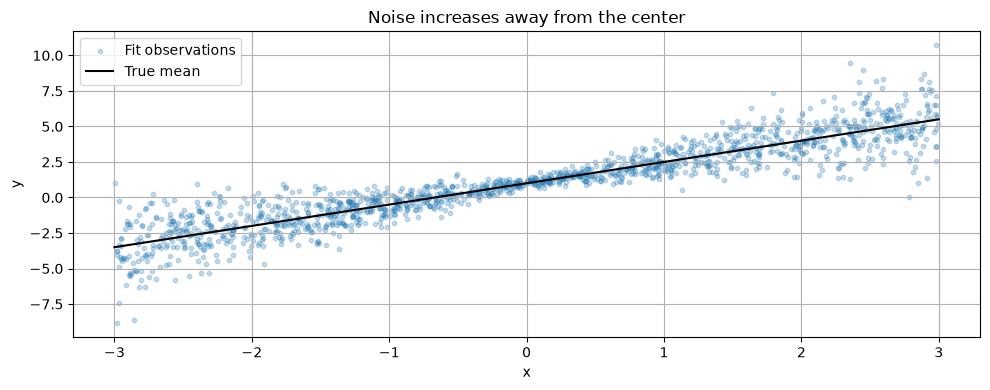

In [10]:
rng_reg = np.random.default_rng(7)
X_reg = rng_reg.uniform(-3, 3, size=(12000, 1))
true_mean = 1 + 1.5 * X_reg[:, 0]
true_scale = 0.2 + 0.5 * np.abs(X_reg[:, 0])
y_reg = true_mean + true_scale * rng_reg.normal(size=len(X_reg))

X_reg_fit, X_reg_remaining, y_reg_fit, y_reg_remaining = train_test_split(
    X_reg, y_reg, test_size=0.5, random_state=7
)
X_reg_calib, X_reg_test, y_reg_calib, y_reg_test = train_test_split(
    X_reg_remaining, y_reg_remaining, test_size=0.5, random_state=8
)

print(
    f"Fit/calibration/test sizes: "
    f"{len(X_reg_fit)}/{len(X_reg_calib)}/{len(X_reg_test)}"
)
print("Target shape:", y_reg_fit.shape)  # One scalar target per observation.

fig, ax = plt.subplots()
ax.scatter(
    X_reg_fit[:1500, 0],
    y_reg_fit[:1500],
    s=10,
    alpha=0.25,
    label="Fit observations",
)
x_grid = np.linspace(-3, 3, 400).reshape(-1, 1)
ax.plot(x_grid[:, 0], 1 + 1.5 * x_grid[:, 0], color="black", label="True mean")
ax.set(xlabel="x", ylabel="y", title="Noise increases away from the center")
ax.legend()
plt.tight_layout()
plt.show()

### 🔮 Learning the mean and difficulty <a class="anchor" id="regression-model"></a>

We split the **fit subset** into two parts. A linear model learns the mean from the first part. On the second part, we compute absolute prediction errors and train a random forest to predict them.

The forest output $\hat\sigma(x)$ is an estimate of difficulty. It need not equal the true conditional standard deviation: here it predicts absolute error, and we only use its ranking to form categories.

Neither the conformal calibration labels nor the test observations are used in these fitting steps.

In [11]:
X_mean_fit, X_difficulty_fit, y_mean_fit, y_difficulty_fit = train_test_split(
    X_reg_fit, y_reg_fit, test_size=0.35, random_state=9
)

mean_model = LinearRegression().fit(X_mean_fit, y_mean_fit)
difficulty_targets = np.abs(
    y_difficulty_fit - mean_model.predict(X_difficulty_fit)
)

difficulty_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=6,
    min_samples_leaf=40,
    random_state=7,
    n_jobs=1,
).fit(X_difficulty_fit, difficulty_targets)

print(f"Mean-model fit size: {len(X_mean_fit)}")
print(f"Difficulty-model fit size: {len(X_difficulty_fit)}")

Mean-model fit size: 3900
Difficulty-model fit size: 2100


### 🗂️ Defining the Mondrian categories <a class="anchor" id="regression-groups"></a>

We define three categories by splitting the training difficulty predictions at their one-third and two-thirds quantiles. The two resulting boundaries are frozen before conformal calibration and reused at prediction time. Calibration categories need not have exactly equal sizes.

[Boström and Johansson (2020)](https://proceedings.mlr.press/v128/bostrom20a/bostrom20a.pdf) also describe approximately equal-sized bins formed from calibration difficulty estimates. Here we choose training-only boundaries so that the category rule is fixed independently of calibration. This is an illustrative adaptation, rather than an exact reproduction of their experiments.

*Puncc* passes context fields to `group_function` as keyword arguments. Our function accepts `X_calib` and ignores the others with `**_`. At prediction time, `X_calib` receives the test inputs; no test targets are needed.

Frozen bin boundaries: [0.536 0.961]
Category                Calibration     Test
Low difficulty                 1002     1011
Medium difficulty              1002     1024
High difficulty                 996      965


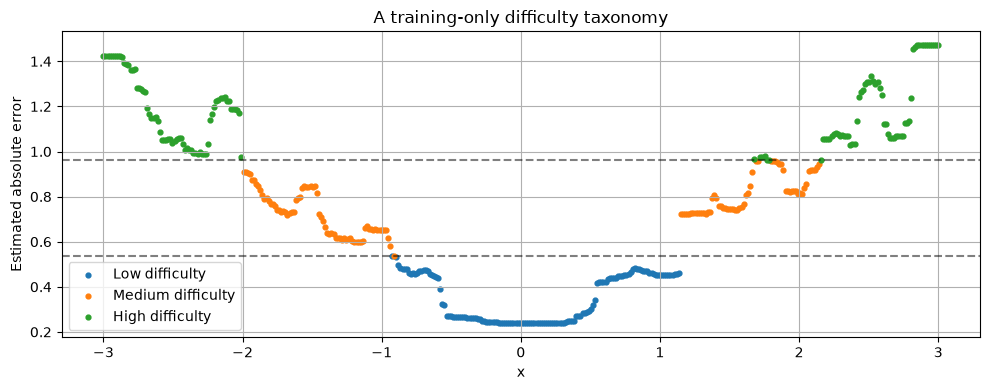

In [12]:
# Predict the training difficulty and define difficulty bins.
training_difficulty = difficulty_model.predict(X_difficulty_fit)
bin_edges = np.quantile(training_difficulty, [1 / 3, 2 / 3])
group_names = ["Low difficulty", "Medium difficulty", "High difficulty"]


# Define a function to assign difficulty groups based on the estimated difficulty.
def difficulty_group(X_calib, **_):
    """Return a fixed difficulty-bin index for every input observation."""
    estimated_difficulty = difficulty_model.predict(X_calib)
    return np.searchsorted(bin_edges, estimated_difficulty, side="right")


# Assign difficulty groups to the calibration and test sets.
calibration_groups = difficulty_group(X_reg_calib)
test_groups = difficulty_group(X_reg_test)
print("Frozen bin boundaries:", np.round(bin_edges, 3))
print(f"{'Category':<22} {'Calibration':>12} {'Test':>8}")
for b, name in enumerate(group_names):
    print(
        f"{name:<22} {(calibration_groups == b).sum():>12} "
        f"{(test_groups == b).sum():>8}"
    )

fig, ax = plt.subplots()
grid_groups = difficulty_group(x_grid)
for b, name in enumerate(group_names):
    mask = grid_groups == b
    ax.scatter(
        x_grid[mask, 0],
        difficulty_model.predict(x_grid[mask]),
        s=12,
        label=name,
    )
for edge in bin_edges:
    ax.axhline(edge, color="black", linestyle="--", alpha=0.5)
ax.set(
    xlabel="x",
    ylabel="Estimated absolute error",
    title="A training-only difficulty taxonomy",
)
ax.legend()
plt.tight_layout()
plt.show()

### ⚙️ Group-conditional calibration <a class="anchor" id="regression-calibration"></a>

*Puncc* provides a generic `GroupConditionalMixin`. Placing it **before** `SplitConformalRegression` makes the group routing run before the ordinary interval construction.

The mixin partitions calibration scores, routes each test observation to its category, and restores the original test order after constructing the intervals. We only need to provide the taxonomy.

Both conformal predictors below reuse the already fitted mean model. Calling `fit` again would change the predictor, so we proceed directly to `calibrate`.

In [13]:
# Define the Mondrian regression model
class MondrianRegression(GroupConditionalMixin, SplitConformalRegression):
    """Split conformal regression calibrated within observable categories."""


mondrian_regressor = MondrianRegression(
    model=mean_model,
    group_function=difficulty_group,
)

# Define the marginal regression model
marginal_regressor = SplitConformalRegression(model=mean_model)

# Calibrate the regression models
mondrian_regressor.calibrate(X_reg_calib, y_reg_calib)
marginal_regressor.calibrate(X_reg_calib, y_reg_calib)

# Make predictions with the regression models
reg_prediction, mondrian_intervals = mondrian_regressor.predict(
    X_reg_test, alpha=alpha
)
_, marginal_intervals = marginal_regressor.predict(X_reg_test, alpha=alpha)

print("Point predictions:", reg_prediction.shape)
print("Prediction intervals:", mondrian_intervals.shape)

Point predictions: (3000,)
Prediction intervals: (3000, 2)


### 📏 Coverage and interval width by category <a class="anchor" id="regression-metrics"></a>

Let us first compute the marginal metrics, then repeat the calculation within each difficulty category. A global interval can be unnecessarily wide for easy observations and too narrow for difficult ones, even when its marginal coverage is close to the target.

Method                 Coverage   Mean width
Split conformal           0.908        3.543
Mondrian                  0.919        3.244

Category               Method                 Coverage   Mean width
Low difficulty         Split conformal           0.999        3.543
Low difficulty         Mondrian                  0.925        1.631
Medium difficulty      Split conformal           0.931        3.543
Medium difficulty      Mondrian                  0.909        3.252
High difficulty        Split conformal           0.788        3.543
High difficulty        Mondrian                  0.924        4.926


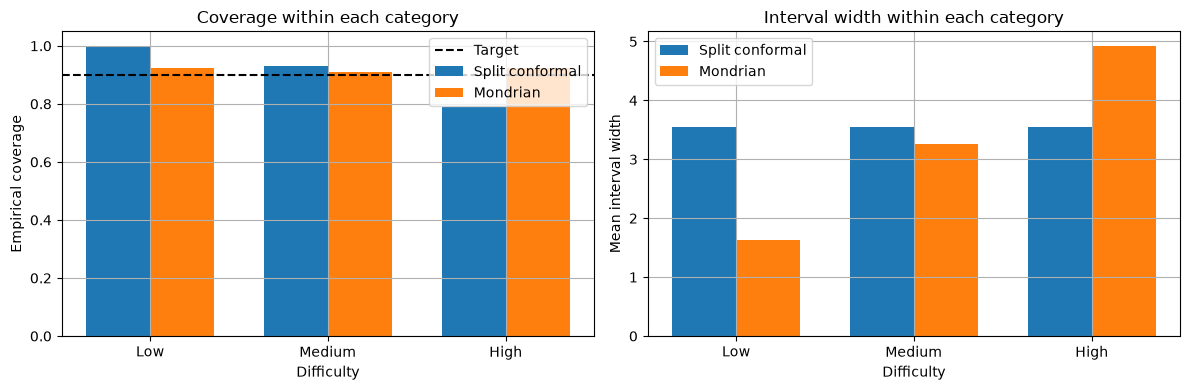

In [14]:
reg_intervals = {
    "Split conformal": marginal_intervals,
    "Mondrian": mondrian_intervals,
}

# Evaluate the regression models on the test set
print(f"{'Method':<20} {'Coverage':>10} {'Mean width':>12}")
for name, intervals in reg_intervals.items():
    lower, upper = intervals[:, 0], intervals[:, 1]
    coverage = regression_mean_coverage(y_reg_test, lower, upper)
    mean_width = float(regression_sharpness(lower, upper))
    print(f"{name:<20} {coverage:>10.3f} {mean_width:>12.3f}")

reg_metrics = {}
for name, intervals in reg_intervals.items():
    coverages, widths = [], []
    for b in range(len(group_names)):
        mask = test_groups == b
        if not np.any(mask):
            coverages.append(np.nan)
            widths.append(np.nan)
            continue
        lower, upper = intervals[mask, 0], intervals[mask, 1]
        coverages.append(
            regression_mean_coverage(y_reg_test[mask], lower, upper)
        )
        widths.append(float(regression_sharpness(lower, upper)))
    reg_metrics[name] = (np.asarray(coverages), np.asarray(widths))

# Print a summary of the coverage and interval width within each difficulty category
print()
print(f"{'Category':<22} {'Method':<20} {'Coverage':>10} {'Mean width':>12}")
for b, group_name in enumerate(group_names):
    for name, (coverages, widths) in reg_metrics.items():
        print(
            f"{group_name:<22} {name:<20} {coverages[b]:>10.3f} {widths[b]:>12.3f}"
        )

# Visualize the coverage and interval width within each difficulty category
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(group_names))
width = 0.36
for offset, (name, (coverage, interval_width)) in zip(
    [-width / 2, width / 2], reg_metrics.items()
):
    axes[0].bar(positions + offset, coverage, width, label=name)
    axes[1].bar(positions + offset, interval_width, width, label=name)
axes[0].axhline(1 - alpha, color="black", linestyle="--", label="Target")
axes[0].set(
    ylabel="Empirical coverage",
    ylim=(0, 1.05),
    title="Coverage within each category",
)
axes[1].set(
    ylabel="Mean interval width", title="Interval width within each category"
)
for ax in axes:
    ax.set(
        xticks=positions,
        xticklabels=["Low", "Medium", "High"],
        xlabel="Difficulty",
    )
    ax.legend()
plt.tight_layout()
plt.show()

Each Mondrian category has its own half-width, although the interval center still changes with the model prediction. Observations with different inputs can belong to the same difficulty category.

We display the same random subset of 500 test observations in both panels. The coverage shown in each title refers to this displayed subset; the tables above report coverage on the full test set. Neither the categories nor the thresholds are changed after looking at these plots.

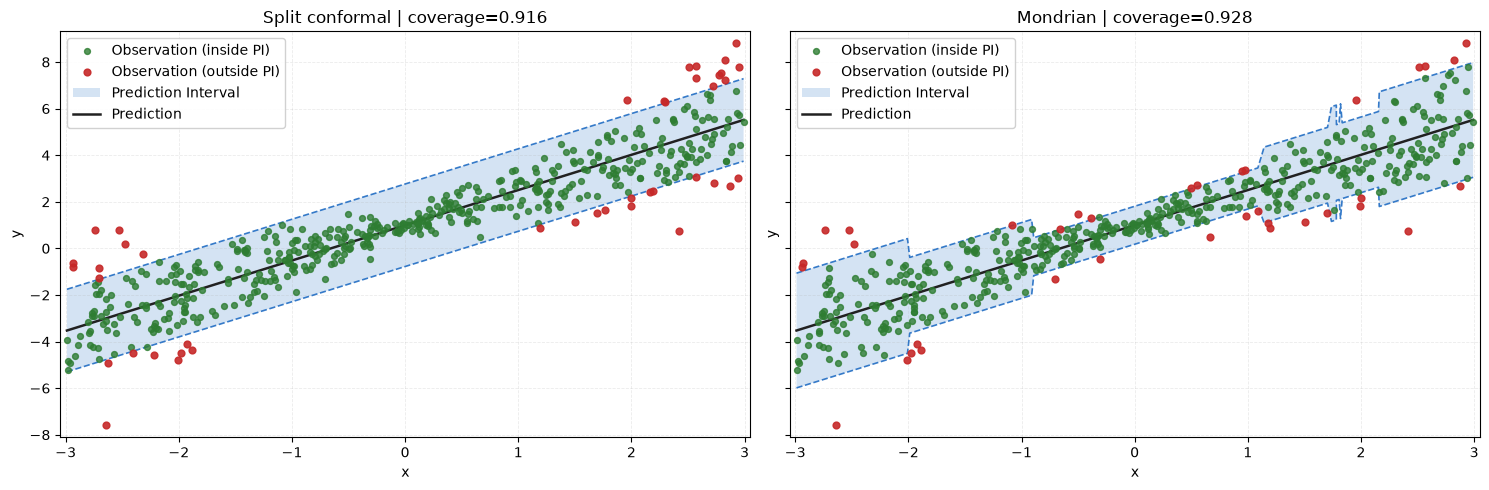

In [15]:
# Use the same random test subset in both panels to keep the plot readable.
shown = np.random.default_rng(10).choice(
    len(X_reg_test), size=500, replace=False
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, intervals) in zip(axes, reg_intervals.items()):
    # The puncc helper sorts X and aligns the observations and interval bounds.
    plot_prediction_intervals(
        X=X_reg_test[shown, 0],
        y_true=y_reg_test[shown],
        y_pred=reg_prediction[shown],
        y_pred_lower=intervals[shown, 0],
        y_pred_upper=intervals[shown, 1],
        ax=ax,
        title=name,
        loc="upper left",
    )
    ax.set(xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()

### 🔍 Inspecting the group-specific thresholds <a class="anchor" id="regression-thresholds"></a>

Finally, we compute each category's threshold independently and compare the expected interval to puncc's output **for every test observation in its original order**. This also checks that the grouped predictions have been reassembled correctly.

The public grouping implementation stores category contexts in `group_calibration_contexts`. We can inspect the count in each context without relying on a global calibration-score array.

In [16]:
reg_scores = np.abs(y_reg_calib - mean_model.predict(X_reg_calib))
group_thresholds = np.array(
    [
        conformal_threshold(reg_scores[calibration_groups == b], alpha)
        for b in range(len(group_names))
    ]
)

print(f"{'Category':<22} {'Calibration size':>18} {'Half-width':>12}")
for b, name in enumerate(group_names):
    context = mondrian_regressor.group_calibration_contexts[b]
    assert context.size == (calibration_groups == b).sum()
    print(f"{name:<22} {context.size:>18} {group_thresholds[b]:>12.3f}")

expected_half_width = group_thresholds[test_groups]
expected_intervals = np.column_stack(
    [
        reg_prediction - expected_half_width,
        reg_prediction + expected_half_width,
    ]
)
np.testing.assert_allclose(
    mondrian_intervals, expected_intervals, rtol=1e-7, atol=1e-7
)
print(
    "All intervals match the category-specific thresholds and original test order."
)

Category                 Calibration size   Half-width
Low difficulty                       1002        0.815
Medium difficulty                    1002        1.626
High difficulty                       996        2.463
All intervals match the category-specific thresholds and original test order.


## ✅ Choosing and evaluating categories <a class="anchor" id="takeaways"></a>

You have now implemented two Mondrian conformal predictors with *puncc*. Both calibrate within categories, but they use those categories differently at prediction time.

| Question | Classification example | Regression example |
|---|---|---|
| How is the category defined? | By the true class during calibration | By a fixed difficulty-bin function |
| What happens at prediction time? | Test every candidate class against its threshold | Route each input to its observable category |
| What is returned? | A set of class indices | A lower and an upper bound |
| What should we evaluate? | Coverage and mean set size by true class | Coverage and mean interval width by category |

A few practical points are useful when adapting these examples:

- **Keep calibration separate from fitting.** Train models, preprocessing and learned categories before calibration, then freeze them. Changing a model or category rule requires recalibration.
- **Check category sizes.** More categories mean fewer scores per category. If $\alpha<1/(n_{category}+1)$, the corrected threshold is infinite. Finer categories do not automatically produce more useful predictions.
- **Keep the inference rule fixed.** Never recompute quantile bin boundaries independently for each test batch, and never use unknown regression targets to assign groups.
- **Interpret coverage at the category level.** A difficulty-bin guarantee does not imply coverage conditional on every individual input, nor does one finite test run establish the guarantee.

### 🎉 Congratulations!

You can now use `ClassConditionalLAC` for label-conditional classification and compose `GroupConditionalMixin` with `SplitConformalRegression` for observable-group regression. For more ways to customize the workflow, continue with the [custom conformalization tutorial](puncc_custom_conformalization.ipynb).